# Guided: two features and three columns: engineer and audit them together
*Feature engineering from the customer table · Leakage and the prediction-time question ·
The column audit*

The trainer leads; the room fills the three TODO cells together, says each reason aloud,
and runs the check cell. The worked answer sits in the last section, below a clear line, so
the room tries first. Nothing here needs more than one line of pandas per answer.

**Who needs the answer.** The campaign head, who will ask "why that feature?", and the
solution architect, who will ask "is that column there when we score?".

**The questions on the way.** Which line turns the 999 sentinel into a never-contacted flag?
Which line stamps a previous success? Which of three columns pass the prediction-time
question? What do the two features add?

**Search terms:** feature engineering pandas, data leakage checklist.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline every case notebook starts from: the same file, columns, split and baseline.
import io, zipfile, pathlib, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
# Joined on Wednesday from other feeds: the call log and the economic indicators.
CALL_LOG = ["duration"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

bank = load_bank()
train, val, test = week_split(bank)
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)
print(f"{len(bank):,} calls: train {len(train):,}, validation {len(val):,}, "
      f"test {len(test):,} (sealed until Friday)")
print(f"Base rate: {y_train.mean():.2%} of training calls ended in a deposit")

41,188 calls: train 24,712, validation 8,238, test 8,238 (sealed until Friday)
Base rate: 11.27% of training calls ended in a deposit


## Which line turns the 999 sentinel into a never-contacted flag?
`pdays` is days since the client was last contacted in an earlier campaign, and 999 means
never. Pick the line, type it in place of `None`, and write the reason a marketing lead
would repeat.

In [2]:
# TODO 1: replace None with the line that is 1 when the client was never contacted before.
#   (A) (bank["pdays"] == 0).astype(int)
#   (B) (bank["pdays"] == 999).astype(int)
#   (C) bank["pdays"] / 999
never_contacted = None
reason_1 = "TODO: one sentence a marketing lead would repeat"
print("TODO 1 is open" if never_contacted is None else f"never_contacted is 1 in {never_contacted.mean():.1%} of rows")

TODO 1 is open


## Which line stamps a previous success?
`poutcome` says how the client's previous campaign ended: `success`, `failure` or
`nonexistent`. Build a 0 or 1 flag for a previous success and give its reason.

In [3]:
# TODO 2: replace None with the line that is 1 when the previous campaign ended in success.
#   (A) (bank["poutcome"] == "success").astype(int)
#   (B) (bank["poutcome"] != "failure").astype(int)
#   (C) (bank["y"] == "yes").astype(int)
prior_success = None
reason_2 = "TODO: one sentence a marketing lead would repeat"
print("TODO 2 is open" if prior_success is None else f"prior_success is 1 in {prior_success.mean():.1%} of rows")

TODO 2 is open


## Which of three columns pass the prediction-time question?
On the morning the call list is made, do we know this value for this client? Write
`"known"` or `"not known"` for each column, and the system that writes it.

In [4]:
# TODO 3: fill each pair as ("known" or "not known", "the system that writes it and when").
audit = {"duration": None, "euribor3m": None, "poutcome": None}
open_items = [c for c, v in audit.items() if v is None]
print("TODO 3 is open for:", open_items if open_items else "nothing; run the check cell")

TODO 3 is open for: ['duration', 'euribor3m', 'poutcome']


## Did the room's answers hold?
Run this once the three TODO cells are filled. It reports each answer and, when all three
are in, scores the honest feature set with the two new flags.

In [5]:
if never_contacted is None or prior_success is None or None in audit.values():
    print("Waiting: fill TODO 1, 2 and 3 above, then run this cell again.")
else:
    check("never_contacted is 1 for about 96 percent of rows", 0.95 < never_contacted.mean() < 0.97)
    check("prior_success is 1 for about 3 percent of rows", 0.03 < prior_success.mean() < 0.04)
    check("duration is the column that is not known", audit["duration"][0] == "not known"
          and audit["poutcome"][0] == "known")

Waiting: fill TODO 1, 2 and 3 above, then run this cell again.


---
## What is the worked answer?
**TODO 1 is B.** Reason: "most clients have never heard from us, and the ones who have
convert far more often." Option A flags clients contacted zero days ago; option C turns a
sentinel into a fake number of days.

**TODO 2 is A.** Reason: "a client who said yes last time is the warmest call we have."
Option B also stamps the 35,563 clients with no previous campaign; option C copies the
target into a feature, which is the leak in its purest form.

**TODO 3.** `duration` is not known (the call log writes it when the call ends);
`euribor3m` is known (the research desk publishes it daily, before the call), with the
calendar caveat of case 2; `poutcome` is known (the previous campaign closed months before).

In [6]:
never_contacted = (bank["pdays"] == 999).astype(int)
prior_success = (bank["poutcome"] == "success").astype(int)
audit = {"duration": ("not known", "call log, when the call ends"),
         "euribor3m": ("known", "research desk, published daily"),
         "poutcome": ("known", "campaign history, when the last campaign closed")}
bank = bank.assign(never_contacted=never_contacted, prior_success=prior_success)
train, val, test = week_split(bank)
y_train, y_val = (train["y"] == "yes").astype(int), (val["y"] == "yes").astype(int)
def auc(cols):
    model = logistic(cols, train).fit(train[cols], y_train)
    return round(roc_auc_score(y_val, model.predict_proba(val[cols])[:, 1]), 4)
before = auc(PROFILE + HISTORY + ECONOMY)
after = auc(PROFILE + HISTORY + ECONOMY + ["never_contacted", "prior_success"])
print(f"customer table + economy: {before}; with the two flags: {after}")
check("never_contacted is 1 for about 96 percent of rows", 0.95 < never_contacted.mean() < 0.97)
check("prior_success is 1 for about 3 percent of rows", 0.03 < prior_success.mean() < 0.04)
check("duration is the column that is not known", audit["duration"][0] == "not known" and audit["poutcome"][0] == "known")

customer table + economy: 0.7946; with the two flags: 0.7952
PASS  never_contacted is 1 for about 96 percent of rows
PASS  prior_success is 1 for about 3 percent of rows
PASS  duration is the column that is not known


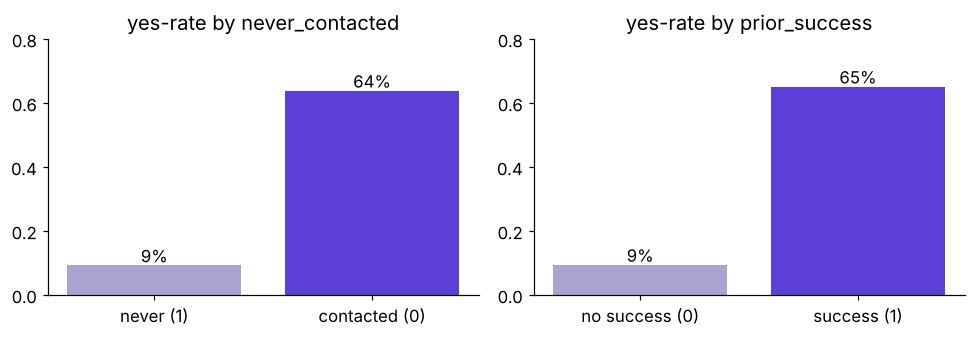

In [7]:
rates = pd.DataFrame({
    "never contacted": [bank.loc[never_contacted == 1, "y"].eq("yes").mean(), bank.loc[never_contacted == 0, "y"].eq("yes").mean()],
    "previous success": [bank.loc[prior_success == 0, "y"].eq("yes").mean(), bank.loc[prior_success == 1, "y"].eq("yes").mean()],
}, index=["flag = 1 / 0", "flag = 0 / 1"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (name, a, b, la, lb) in zip(axes, [
        ("never_contacted", rates.iloc[0, 0], rates.iloc[1, 0], "never (1)", "contacted (0)"),
        ("prior_success", rates.iloc[0, 1], rates.iloc[1, 1], "no success (0)", "success (1)")]):
    ax.bar([la, lb], [a, b], color=[GREY, VIOLET])
    for i, v in enumerate([a, b]):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=11)
    ax.set_ylim(0, 0.8); ax.set_title(f"yes-rate by {name}")
plt.tight_layout(); plt.show()

**What the room should say aloud.** Both flags pass the prediction-time question and carry
a reason; the AUC barely moves because `poutcome` and `pdays` already held the signal, and
the flags make it readable. The flip: if a flag's reason cannot be said in one sentence to
the campaign head, it does not ship, whatever it adds.